<a href="https://colab.research.google.com/github/Bteja272/ATLAS/blob/main/ATLAS.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!pip -q install --upgrade mediapipe


In [ ]:
from pathlib import Path
import math
import os

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import mediapipe as mp
from mediapipe.tasks import python
from mediapipe.tasks.python import vision

from google.colab import files
from IPython.display import Video, display
import requests
from pathlib import Path

WORKDIR = Path("/content/atlas")
WORKDIR.mkdir(parents=True, exist_ok=True)

MODEL_PATH = WORKDIR / "pose_landmarker_full.task"
OUTPUT_VIDEO = WORKDIR / "atlas_pose_annotated.mp4"
LANDMARK_CSV = WORKDIR / "atlas_landmarks.csv"
ANGLE_CSV = WORKDIR / "atlas_angles.csv"

print("Working directory:", WORKDIR)

Working directory: /content/atlas


In [ ]:
if not MODEL_PATH.exists():
    !wget -q -O {MODEL_PATH} https://storage.googleapis.com/mediapipe-models/pose_landmarker/pose_landmarker_full/float16/1/pose_landmarker_full.task

print("Model exists:", MODEL_PATH.exists())
print("Model path:", MODEL_PATH)

Model exists: True
Model path: /content/atlas/pose_landmarker_full.task


In [ ]:
# Install/update yt-dlp
!pip -q install -U "yt-dlp[default]"

from pathlib import Path
import yt_dlp

VIDEO_URL = "https://www.youtube.com/shorts/2QmWgPtO5yc"

VIDEO_PATH = WORKDIR / "input_video.mp4"

# IMPORTANT:
# Remove any previous file.
# Our earlier requests-based attempt saved HTML with an .mp4 extension.
if VIDEO_PATH.exists():
    VIDEO_PATH.unlink()
    print("Removed old input_video.mp4")

ydl_opts = {
    # Prefer a format OpenCV can normally decode.
    "format": "bestvideo[ext=mp4]+bestaudio[ext=m4a]/best[ext=mp4]/best",

    "outtmpl": str(VIDEO_PATH),

    "merge_output_format": "mp4",

    # Never reuse an old/broken file.
    "overwrites": True,

    "noplaylist": True,
    "quiet": False,
}

with yt_dlp.YoutubeDL(ydl_opts) as ydl:
    info = ydl.extract_info(VIDEO_URL, download=True)

print("\nDownloaded video:", VIDEO_PATH)
print("Exists:", VIDEO_PATH.exists())

if VIDEO_PATH.exists():
    print(
        "Size:",
        round(VIDEO_PATH.stat().st_size / (1024 * 1024), 2),
        "MB"
    )

Removed old input_video.mp4
[youtube] Extracting URL: https://www.youtube.com/shorts/2QmWgPtO5yc
[youtube] 2QmWgPtO5yc: Downloading webpage


[youtube] 2QmWgPtO5yc: Downloading visionos player API JSON
[youtube] 2QmWgPtO5yc: Downloading m3u8 information
[info] 2QmWgPtO5yc: Downloading 1 format(s): 616+140-18
[hlsnative] Downloading m3u8 manifest
[hlsnative] Total fragments: 11
[download] Destination: /content/atlas/input_video.f616.mp4
[download] 100% of   24.49MiB in 00:00:06 at 3.76MiB/s                 
[download] Destination: /content/atlas/input_video.f140-18.m4a
[download] 100% of  947.18KiB in 00:00:00 at 1.77MiB/s   
[Merger] Merging formats into "/content/atlas/input_video.mp4"
Deleting original file /content/atlas/input_video.f616.mp4 (pass -k to keep)
Deleting original file /content/atlas/input_video.f140-18.m4a (pass -k to keep)

Downloaded video: /content/atlas/input_video.mp4
Exists: True
Size: 25.44 MB


In [ ]:
import cv2

print("File exists:", VIDEO_PATH.exists())

if not VIDEO_PATH.exists():
    raise FileNotFoundError("yt-dlp did not create the expected video file.")

cap = cv2.VideoCapture(str(VIDEO_PATH))

if not cap.isOpened():
    raise RuntimeError(
        f"Video downloaded, but OpenCV could not open it: {VIDEO_PATH}"
    )

fps = cap.get(cv2.CAP_PROP_FPS)
frame_count = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
width = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))

duration = frame_count / fps if fps else 0

cap.release()

print(f"FPS: {fps:.2f}")
print(f"Frames: {frame_count}")
print(f"Resolution: {width} x {height}")
print(f"Duration: {duration:.2f} seconds")

File exists: True
FPS: 30.00
Frames: 1795
Resolution: 1080 x 1920
Duration: 59.83 seconds


In [ ]:
cap = cv2.VideoCapture(str(VIDEO_PATH))

if not cap.isOpened():
    raise RuntimeError(f"Could not open video: {VIDEO_PATH}")

fps = cap.get(cv2.CAP_PROP_FPS)
frame_count = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
width = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))

duration = frame_count / fps if fps else 0

cap.release()

print(f"FPS: {fps:.2f}")
print(f"Frames: {frame_count}")
print(f"Resolution: {width} x {height}")
print(f"Duration: {duration:.2f} seconds")

FPS: 30.00
Frames: 1795
Resolution: 1080 x 1920
Duration: 59.83 seconds


In [ ]:
LANDMARK_NAMES = [
    "nose",
    "left_eye_inner", "left_eye", "left_eye_outer",
    "right_eye_inner", "right_eye", "right_eye_outer",
    "left_ear", "right_ear",
    "mouth_left", "mouth_right",
    "left_shoulder", "right_shoulder",
    "left_elbow", "right_elbow",
    "left_wrist", "right_wrist",
    "left_pinky", "right_pinky",
    "left_index", "right_index",
    "left_thumb", "right_thumb",
    "left_hip", "right_hip",
    "left_knee", "right_knee",
    "left_ankle", "right_ankle",
    "left_heel", "right_heel",
    "left_foot_index", "right_foot_index",
]

POSE_CONNECTIONS = list(mp.tasks.vision.PoseLandmarksConnections.POSE_LANDMARKS)

def draw_pose(frame_bgr, landmarks):
    """Draw MediaPipe pose landmarks and connections on a BGR OpenCV frame."""
    output = frame_bgr.copy()
    h, w = output.shape[:2]

    points = []
    for lm in landmarks:
        x = int(lm.x * w)
        y = int(lm.y * h)
        points.append((x, y))

    # Draw connections first.
    for connection in POSE_CONNECTIONS:
        start = connection.start
        end = connection.end

        if start < len(points) and end < len(points):
            cv2.line(output, points[start], points[end], (0, 255, 0), 2)

    # Draw landmark points.
    for x, y in points:
        cv2.circle(output, (x, y), 4, (0, 0, 255), -1)

    return output

print("Landmarks:", len(LANDMARK_NAMES))

Landmarks: 33


In [ ]:
BaseOptions = mp.tasks.BaseOptions
PoseLandmarker = mp.tasks.vision.PoseLandmarker
PoseLandmarkerOptions = mp.tasks.vision.PoseLandmarkerOptions
RunningMode = mp.tasks.vision.RunningMode

options = PoseLandmarkerOptions(
    base_options=BaseOptions(model_asset_path=str(MODEL_PATH)),
    running_mode=RunningMode.VIDEO,
    num_poses=1,
    min_pose_detection_confidence=0.5,
    min_pose_presence_confidence=0.5,
    min_tracking_confidence=0.5,
)

cap = cv2.VideoCapture(str(VIDEO_PATH))

if not cap.isOpened():
    raise RuntimeError("Could not reopen the video.")

fps = cap.get(cv2.CAP_PROP_FPS)
width = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))

fourcc = cv2.VideoWriter_fourcc(*"mp4v")
writer = cv2.VideoWriter(
    str(OUTPUT_VIDEO),
    fourcc,
    fps,
    (width, height)
)

records = []
detected_frames = 0
frame_idx = 0

with PoseLandmarker.create_from_options(options) as landmarker:
    while True:
        success, frame_bgr = cap.read()
        if not success:
            break

        # Convert OpenCV BGR -> RGB.
        frame_rgb = cv2.cvtColor(frame_bgr, cv2.COLOR_BGR2RGB)

        mp_image = mp.Image(
            image_format=mp.ImageFormat.SRGB,
            data=frame_rgb
        )

        timestamp_ms = int((frame_idx / fps) * 1000)

        result = landmarker.detect_for_video(
            mp_image,
            timestamp_ms
        )

        annotated = frame_bgr.copy()

        if result.pose_landmarks:
            detected_frames += 1

            landmarks = result.pose_landmarks[0]

            world_landmarks = (
                result.pose_world_landmarks[0]
                if result.pose_world_landmarks
                else None
            )

            annotated = draw_pose(annotated, landmarks)

            time_sec = frame_idx / fps

            for landmark_id, lm in enumerate(landmarks):
                world = (
                    world_landmarks[landmark_id]
                    if world_landmarks is not None
                    else None
                )

                records.append({
                    "frame": frame_idx,
                    "time_sec": time_sec,
                    "landmark_id": landmark_id,
                    "landmark": LANDMARK_NAMES[landmark_id],
                    "x": lm.x,
                    "y": lm.y,
                    "z": lm.z,
                    "visibility": lm.visibility,
                    "presence": lm.presence,
                    "world_x": world.x if world else np.nan,
                    "world_y": world.y if world else np.nan,
                    "world_z": world.z if world else np.nan,
                    "world_visibility": world.visibility if world else np.nan,
                })

        cv2.putText(
            annotated,
            f"ATLAS | Frame {frame_idx}",
            (20, 35),
            cv2.FONT_HERSHEY_SIMPLEX,
            0.8,
            (255, 255, 255),
            2,
            cv2.LINE_AA,
        )

        writer.write(annotated)
        frame_idx += 1

cap.release()
writer.release()

landmarks_df = pd.DataFrame(records)
landmarks_df.to_csv(LANDMARK_CSV, index=False)

print(f"Processed frames: {frame_idx}")
print(f"Frames with detected pose: {detected_frames}")
print(f"Detection rate: {detected_frames / max(frame_idx, 1):.1%}")
print(f"Landmark rows: {len(landmarks_df):,}")
print(f"Saved landmarks: {LANDMARK_CSV}")
print(f"Saved annotated video: {OUTPUT_VIDEO}")

Processed frames: 1795
Frames with detected pose: 1766
Detection rate: 98.4%
Landmark rows: 58,278
Saved landmarks: /content/atlas/atlas_landmarks.csv
Saved annotated video: /content/atlas/atlas_pose_annotated.mp4


In [ ]:
display(landmarks_df.head(12))

print("\nShape:", landmarks_df.shape)
print("\nColumns:")
print(list(landmarks_df.columns))

,frame,time_sec,landmark_id,landmark,x,y,z,visibility,presence,world_x,world_y,world_z,world_visibility
0,0,0.0,0,nose,0.308019,0.556925,-0.051718,0.990193,0.981162,-0.523438,0.066275,-0.018784,0.990193
1,0,0.0,1,left_eye_inner,0.290749,0.553006,-0.096842,0.989490,0.987540,-0.561262,0.051029,-0.047822,0.989490
2,0,0.0,2,left_eye,0.290020,0.551411,-0.096978,0.988828,0.988261,-0.561258,0.050717,-0.047153,0.988828
3,0,0.0,3,left_eye_outer,0.289167,0.549579,-0.097180,0.992384,0.989292,-0.561488,0.051478,-0.047643,0.992384
4,0,0.0,4,right_eye_inner,0.290958,0.553380,-0.033936,0.989735,0.988238,-0.559828,0.048538,-0.012707,0.989735
5,0,0.0,5,right_eye,0.290321,0.552134,-0.033982,0.989954,0.989239,-0.560373,0.048229,-0.013746,0.989954
6,0,0.0,6,right_eye_outer,0.289505,0.550593,-0.034084,0.992743,0.990318,-0.561923,0.048721,-0.012934,0.992743
7,0,0.0,7,left_ear,0.294119,0.532719,-0.210584,0.993106,0.993749,-0.541537,-0.049760,-0.109468,0.993106
8,0,0.0,8,right_ear,0.294637,0.533719,0.074951,0.994278,0.995177,-0.554728,-0.061805,0.037481,0.994278
9,0,0.0,9,mouth_left,0.327342,0.551300,-0.087969,0.997168,0.997213,-0.496482,0.022488,-0.039591,0.997168



Shape: (58278, 13)

Columns:
['frame', 'time_sec', 'landmark_id', 'landmark', 'x', 'y', 'z', 'visibility', 'presence', 'world_x', 'world_y', 'world_z', 'world_visibility']


In [ ]:
display(Video(str(OUTPUT_VIDEO), embed=True))

In [ ]:
def frame_landmarks(frame_df):
    """Convert one frame's landmark rows into a lookup dictionary."""
    return {
        row["landmark"]: np.array(
            [row["world_x"], row["world_y"], row["world_z"]],
            dtype=float
        )
        for _, row in frame_df.iterrows()
    }

sample_frame_id = landmarks_df["frame"].iloc[0]
sample_lookup = frame_landmarks(
    landmarks_df[landmarks_df["frame"] == sample_frame_id]
)

sample_lookup["left_shoulder"]

array([-0.38061801, -0.06684656, -0.19176537])

In [ ]:
def calculate_angle(a, b, c):
    """Return angle ABC in degrees for 2D/3D points."""
    a = np.asarray(a, dtype=float)
    b = np.asarray(b, dtype=float)
    c = np.asarray(c, dtype=float)

    if np.isnan(a).any() or np.isnan(b).any() or np.isnan(c).any():
        return np.nan

    ba = a - b
    bc = c - b

    denom = np.linalg.norm(ba) * np.linalg.norm(bc)

    if denom == 0:
        return np.nan

    cosine = np.dot(ba, bc) / denom
    cosine = np.clip(cosine, -1.0, 1.0)

    return np.degrees(np.arccos(cosine))


# Quick verification:
# A straight line should be ~180 degrees.
print(
    calculate_angle(
        [0, 0, 0],
        [1, 0, 0],
        [2, 0, 0]
    )
)

180.0


In [ ]:
def torso_inclination_2d(frame_df):
    rows = frame_df.set_index("landmark")

    required = [
        "left_shoulder", "right_shoulder",
        "left_hip", "right_hip"
    ]

    if not all(name in rows.index for name in required):
        return np.nan

    left_shoulder = rows.loc["left_shoulder", ["x", "y"]].to_numpy(dtype=float)
    right_shoulder = rows.loc["right_shoulder", ["x", "y"]].to_numpy(dtype=float)
    left_hip = rows.loc["left_hip", ["x", "y"]].to_numpy(dtype=float)
    right_hip = rows.loc["right_hip", ["x", "y"]].to_numpy(dtype=float)

    shoulder_mid = (left_shoulder + right_shoulder) / 2
    hip_mid = (left_hip + right_hip) / 2

    torso_vector = shoulder_mid - hip_mid

    # Image y-axis points downward, but absolute inclination is all we need.
    vertical = np.array([0.0, -1.0])

    denom = np.linalg.norm(torso_vector) * np.linalg.norm(vertical)

    if denom == 0:
        return np.nan

    cosine = np.dot(torso_vector, vertical) / denom
    cosine = np.clip(cosine, -1.0, 1.0)

    return np.degrees(np.arccos(cosine))

In [ ]:
angle_records = []

for frame_id, frame_df in landmarks_df.groupby("frame"):
    p = frame_landmarks(frame_df)

    record = {
        "frame": frame_id,
        "time_sec": frame_df["time_sec"].iloc[0],

        "left_elbow_angle": calculate_angle(
            p["left_shoulder"],
            p["left_elbow"],
            p["left_wrist"]
        ),

        "right_elbow_angle": calculate_angle(
            p["right_shoulder"],
            p["right_elbow"],
            p["right_wrist"]
        ),

        "left_shoulder_angle": calculate_angle(
            p["left_elbow"],
            p["left_shoulder"],
            p["left_hip"]
        ),

        "right_shoulder_angle": calculate_angle(
            p["right_elbow"],
            p["right_shoulder"],
            p["right_hip"]
        ),

        "left_hip_angle": calculate_angle(
            p["left_shoulder"],
            p["left_hip"],
            p["left_knee"]
        ),

        "right_hip_angle": calculate_angle(
            p["right_shoulder"],
            p["right_hip"],
            p["right_knee"]
        ),

        "left_knee_angle": calculate_angle(
            p["left_hip"],
            p["left_knee"],
            p["left_ankle"]
        ),

        "right_knee_angle": calculate_angle(
            p["right_hip"],
            p["right_knee"],
            p["right_ankle"]
        ),

        "torso_inclination": torso_inclination_2d(frame_df),
    }

    record["elbow_asymmetry"] = abs(
        record["left_elbow_angle"] -
        record["right_elbow_angle"]
    )

    angle_records.append(record)

angles_df = pd.DataFrame(angle_records)
angles_df.to_csv(ANGLE_CSV, index=False)

display(angles_df.head())

print("Saved angles:", ANGLE_CSV)

,frame,time_sec,left_elbow_angle,right_elbow_angle,left_shoulder_angle,right_shoulder_angle,left_hip_angle,right_hip_angle,left_knee_angle,right_knee_angle,torso_inclination,elbow_asymmetry
0,0,0.000000,134.043532,136.082467,53.768843,48.061772,55.562778,44.738783,105.148894,99.445082,82.822980,2.038935
1,1,0.033333,138.719222,140.995058,60.112903,50.389370,55.646984,47.296907,112.129029,106.088162,82.707034,2.275836
2,2,0.066666,134.437677,133.919939,56.315535,46.222583,55.047227,47.758416,111.220029,106.524568,82.509309,0.517738
3,3,0.099999,138.421467,134.796821,55.939010,45.578209,55.611536,47.408698,111.174405,104.917480,82.534010,3.624647
4,4,0.133333,136.975364,132.645516,52.297878,43.184286,55.492638,45.819442,110.900463,103.677951,82.162820,4.329848


Saved angles: /content/atlas/atlas_angles.csv


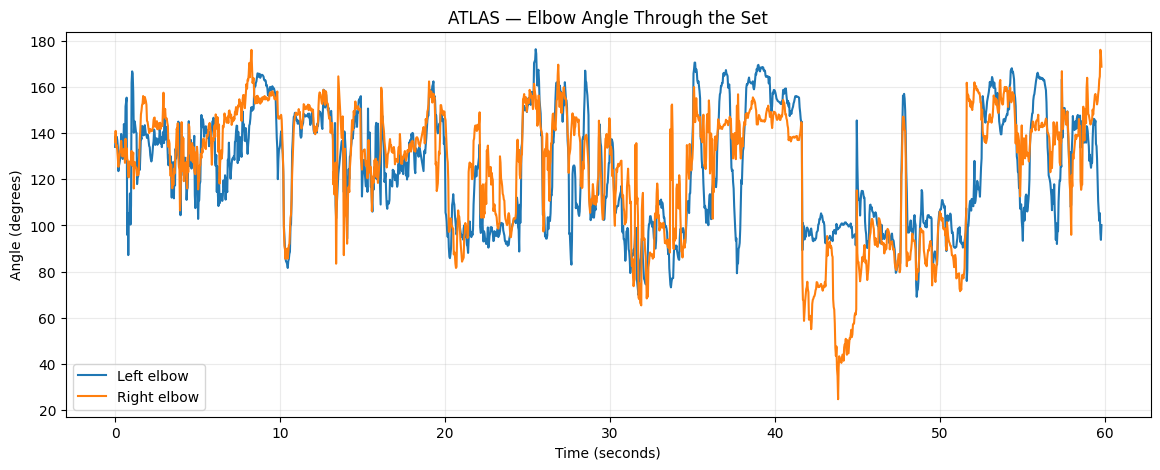

In [ ]:
plt.figure(figsize=(14, 5))

plt.plot(
    angles_df["time_sec"],
    angles_df["left_elbow_angle"],
    label="Left elbow"
)

plt.plot(
    angles_df["time_sec"],
    angles_df["right_elbow_angle"],
    label="Right elbow"
)

plt.xlabel("Time (seconds)")
plt.ylabel("Angle (degrees)")
plt.title("ATLAS — Elbow Angle Through the Set")
plt.legend()
plt.grid(alpha=0.25)
plt.show()

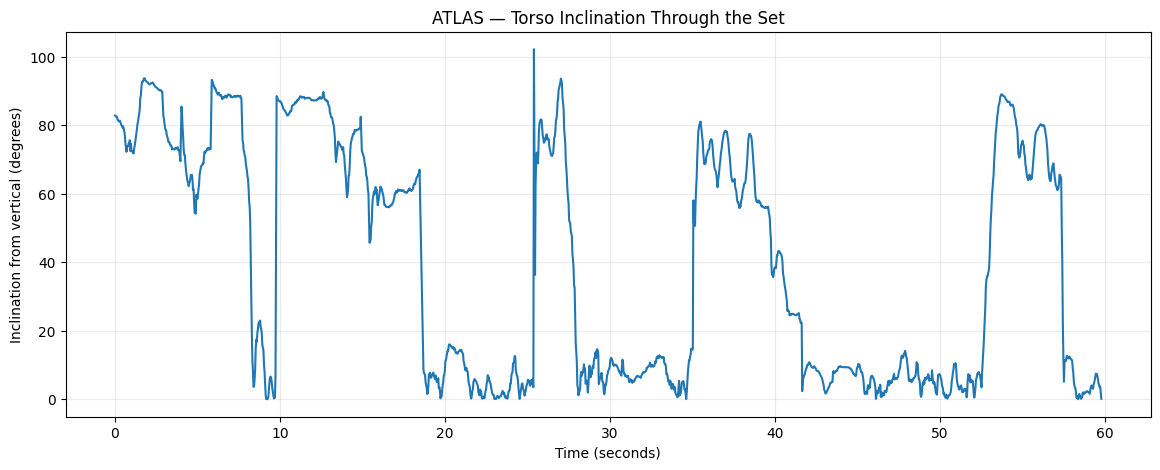

In [ ]:
plt.figure(figsize=(14, 5))

plt.plot(
    angles_df["time_sec"],
    angles_df["torso_inclination"]
)

plt.xlabel("Time (seconds)")
plt.ylabel("Inclination from vertical (degrees)")
plt.title("ATLAS — Torso Inclination Through the Set")
plt.grid(alpha=0.25)
plt.show()

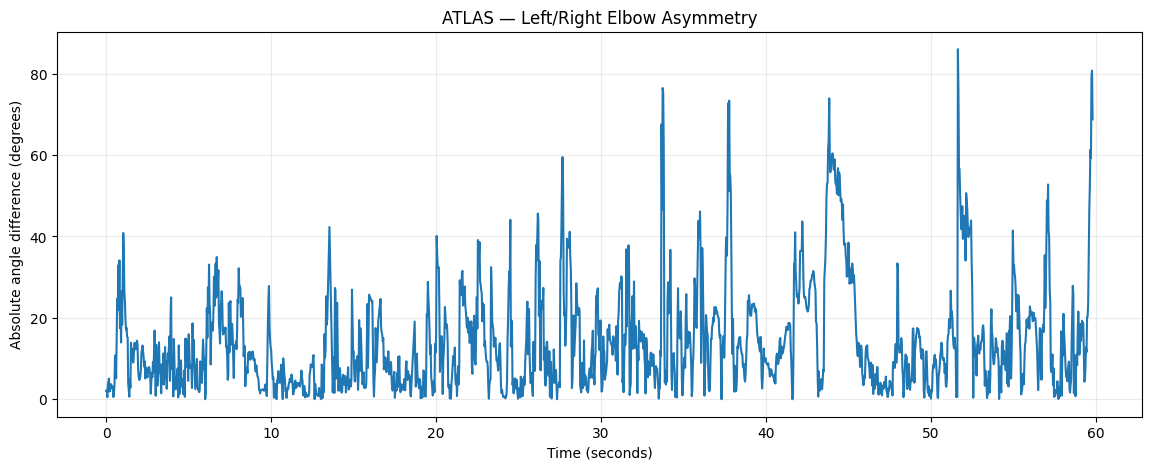

In [ ]:
plt.figure(figsize=(14, 5))

plt.plot(
    angles_df["time_sec"],
    angles_df["elbow_asymmetry"]
)

plt.xlabel("Time (seconds)")
plt.ylabel("Absolute angle difference (degrees)")
plt.title("ATLAS — Left/Right Elbow Asymmetry")
plt.grid(alpha=0.25)
plt.show()

In [ ]:
total_video_frames = frame_count
pose_frames = landmarks_df["frame"].nunique()

summary = pd.DataFrame({
    "metric": [
        "Video frames",
        "Pose-detected frames",
        "Pose detection rate",
        "Mean landmark visibility",
        "Minimum landmark visibility",
    ],
    "value": [
        total_video_frames,
        pose_frames,
        pose_frames / max(total_video_frames, 1),
        landmarks_df["visibility"].mean(),
        landmarks_df["visibility"].min(),
    ]
})

display(summary)

,metric,value
0,Video frames,1795.000000
1,Pose-detected frames,1766.000000
2,Pose detection rate,0.983844
3,Mean landmark visibility,0.790074
4,Minimum landmark visibility,0.012585


In [ ]:
print("Artifacts:")
print("1.", OUTPUT_VIDEO)
print("2.", LANDMARK_CSV)
print("3.", ANGLE_CSV)

# Uncomment any file you want to download locally.
# files.download(str(OUTPUT_VIDEO))
# files.download(str(LANDMARK_CSV))
# files.download(str(ANGLE_CSV))

Artifacts:
1. /content/atlas/atlas_pose_annotated.mp4
2. /content/atlas/atlas_landmarks.csv
3. /content/atlas/atlas_angles.csv
